#### 0. Import Libraries

In [31]:
import matplotlib.pyplot as plt
import numpy as np

#### 1. Table List and Size

In [32]:
from pathlib import Path
import pandas as pd

# Detectar la ruta según si el kernel corre desde 'notebooks/' o desde la raíz
raw_dir = Path('../data/raw') if Path('../data/raw').exists() else Path('data/raw')

# Recorrer ficheros y calcular el tamaño en MB
files_info = [
    {
        "Fichero": f.name,
        "Tamaño (MB)": round(f.stat().st_size / (1024 * 1024), 2)
    }
    for f in sorted(raw_dir.iterdir())
    if f.is_file()
]

# Mostrar como DataFrame
df_files = pd.DataFrame(files_info)
df_files

,Fichero,Tamaño (MB)
0,calendar.csv,0.10
1,sales_train_evaluation.csv,116.10
2,sales_train_validation.csv,114.45
3,sample_submission.csv,4.99
4,sell_prices.csv,193.97


#### 2. Reading the Tables

In [33]:
import pandas as pd
from pathlib import Path

# Diccionario para almacenar los DataFrames
dfs_m5 = {}

# Iterar únicamente sobre los archivos .csv
for f in raw_dir.glob('*.csv'):
    print(f"Cargando {f.name}...")
    # Usamos el nombre del archivo sin extensión (.stem) como clave del diccionario
    dfs_m5[f.stem] = pd.read_csv(f)

print("-" * 40)
print("✅ Todos los ficheros han sido cargados con éxito.")
print(f"Las claves del diccionario son: {list(dfs_m5.keys())}")

Cargando sales_train_evaluation.csv...
Cargando sell_prices.csv...
Cargando calendar.csv...
Cargando sales_train_validation.csv...
Cargando sample_submission.csv...
----------------------------------------
✅ Todos los ficheros han sido cargados con éxito.
Las claves del diccionario son: ['sales_train_evaluation', 'sell_prices', 'calendar', 'sales_train_validation', 'sample_submission']


#### 3. Table Dimensions

In [34]:
# Usar el diccionario dfs_m5 que creamos en el paso anterior
print(f"{'Tabla':<30} | {'Filas':>12} | {'Columnas':>10}")
print("-" * 58)

# Recorrer cada clave y dataframe almacenado en el diccionario
for nombre, df in dfs_m5.items():
    filas, columnas = df.shape
    # Formateamos los números grandes con separador de miles para facilitar la lectura
    print(f"{nombre:<30} | {filas:>12,} | {columnas:>10}")

Tabla                          |        Filas |   Columnas
----------------------------------------------------------
sales_train_evaluation         |       30,490 |       1947
sell_prices                    |    6,841,121 |          4
calendar                       |        1,969 |         14
sales_train_validation         |       30,490 |       1919
sample_submission              |       60,980 |         29


#### 4. Calendar

##### Data Dictionary: `calendar.csv`

This table serves as the temporal dimension of the project. It contains 1,969 historical days and includes calendar variables, special events, and economic assistance indicators.

* **`date`** (`str`): The exact date of the record in `YYYY-MM-DD` format.
* **`wm_yr_wk`** (`int64`): Walmart's accounting/operational week ID (e.g., `11101` for the first week). **Key:** This column is essential because you will use it to join the calendar with the price table (`sell_prices`).
* **`weekday`** (`str`): Name of the day of the week in text (e.g., *Saturday*, *Sunday*).
* **`wday`** (`int64`): Numeric identifier for the day of the week (where 1 corresponds to Saturday and 7 to Friday).
* **`month`** (`int64`): Month of the year as a number (1 to 12).
* **`year`** (`int64`): Year of the date (e.g., 2011).
* **`d`** (`str`): Unique sequential day identifier (e.g., `d_1`, `d_2`, `d_3`...). **Key:** This field is the direct link to the main sales matrix (`sales_train_evaluation`), as each of these identifiers appears as a column there.
* **`event_name_1`** (`str`): Name of the holiday or special event occurring on that day (e.g., *Super Bowl*, *Christmas*). You will notice it has 91.77% missing values (1,807 missing vs. 162 valid), as the vast majority of days are regular working days.
* **`event_type_1`** (`str`): Category to which `event_name_1` belongs (Sporting, Cultural, National, or Religious). It also shares 91.77% missing values.
* **`event_name_2`** and **`event_type_2`** (`str`): Name and type of a second event, used only for rare cases where two holidays overlap on the same date. They have 99.75% missing values.
* **`snap_CA`**, **`snap_TX`**, **`snap_WI`** (`int64`): Binary variables (0 or 1) indicating whether state food assistance coupons (SNAP) can be used on that day in California, Texas, and Wisconsin stores, respectively. In the grocery retail sector, these days drive massive demand spikes.

In [35]:
df_cal = dfs_m5['calendar']

# 1. Resumen de tipos de datos, memoria y nulos
print("=== GENERAL INFORMATION AND NULL VALUES ===")
display(
    pd.DataFrame({
        'Dtype': df_cal.dtypes,
        'Valores_No_Nulos': df_cal.notnull().sum(),
        'Nulos': df_cal.isnull().sum(),
        '%_Nulos': (df_cal.isnull().mean() * 100).round(2),
        'Valores_Unicos': df_cal.nunique()
    })
)

# 2. Vista preliminar de los datos
print("\n=== FIRST ROWS ===")
df_cal.head()

=== GENERAL INFORMATION AND NULL VALUES ===


,Dtype,Valores_No_Nulos,Nulos,%_Nulos,Valores_Unicos
date,str,1969,0,0.00,1969
wm_yr_wk,int64,1969,0,0.00,282
weekday,str,1969,0,0.00,7
wday,int64,1969,0,0.00,7
month,int64,1969,0,0.00,12
year,int64,1969,0,0.00,6
d,str,1969,0,0.00,1969
event_name_1,str,162,1807,91.77,30
event_type_1,str,162,1807,91.77,4
event_name_2,str,5,1964,99.75,4



=== FIRST ROWS ===


,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,Saturday,1,1,2011,d_1,NaN,NaN,NaN,NaN,0,0,0
1,2011-01-30,11101,Sunday,2,1,2011,d_2,NaN,NaN,NaN,NaN,0,0,0
2,2011-01-31,11101,Monday,3,1,2011,d_3,NaN,NaN,NaN,NaN,0,0,0
3,2011-02-01,11101,Tuesday,4,2,2011,d_4,NaN,NaN,NaN,NaN,1,1,0
4,2011-02-02,11101,Wednesday,5,2,2011,d_5,NaN,NaN,NaN,NaN,1,0,1


In [36]:
# Convertir a datetime para asegurar un cálculo y formateo correcto
fecha_min = pd.to_datetime(df_cal['date']).min().strftime('%Y-%m-%d')
fecha_max = pd.to_datetime(df_cal['date']).max().strftime('%Y-%m-%d')
dias_totales = df_cal['date'].nunique()

print(f"=== RANGO TEMPORAL EN CALENDAR ===")
print(f"Fecha mínima : {fecha_min}")
print(f"Fecha máxima : {fecha_max}")
print(f"Total días   : {dias_totales} días")

=== RANGO TEMPORAL EN CALENDAR ===
Fecha mínima : 2011-01-29
Fecha máxima : 2016-06-19
Total días   : 1969 días


#### 5. Sell Prices

##### Diccionario de Datos: `sell_prices.csv`

Esta tabla contiene el registro histórico de precios de venta semanales por producto y tienda. Es fundamental para calcular la elasticidad-precio, detectar promociones y estimar ingresos en el simulador.

* **`store_id`** (`str`): Identificador único de la tienda donde se vende el producto (ej. `CA_1`, `TX_2`).
* **`item_id`** (`str`): Identificador único del producto (SKU) (ej. `HOBBIES_1_001`).
* **`wm_yr_wk`** (`int64`): ID de la semana contable/operativa de Walmart. **Clave:** Esta columna es el nexo para cruzar los precios con la dimensión temporal en `calendar.csv`.
* **`sell_price`** (`float64`): El precio de venta al público fijado para ese producto (`item_id`), en esa tienda (`store_id`), durante esa semana específica (`wm_yr_wk`).

In [37]:
df_prices = dfs_m5['sell_prices']

In [38]:
print("=== GENERAL INFORMATION AND NULL VALUES ===")
display(
    pd.DataFrame({
        'Dtype': df_prices.dtypes,
        'Valores_No_Nulos': df_prices.notnull().sum(),
        'Nulos': df_prices.isnull().sum(),
        '%_Nulos': (df_prices.isnull().mean() * 100).round(2),
        'Valores_Unicos': df_prices.nunique()
    })
)

print("\n=== STATISTICAL DISTRIBUTION OF PRICES ===")
display(df_prices['sell_price'].describe().round(2).to_frame().T)

print("=== FIRST ROWS ===")
df_prices.head()

=== GENERAL INFORMATION AND NULL VALUES ===


,Dtype,Valores_No_Nulos,Nulos,%_Nulos,Valores_Unicos
store_id,str,6841121,0,0.0,10
item_id,str,6841121,0,0.0,3049
wm_yr_wk,int64,6841121,0,0.0,282
sell_price,float64,6841121,0,0.0,1048



=== STATISTICAL DISTRIBUTION OF PRICES ===


,count,mean,std,min,25%,50%,75%,max
sell_price,6841121.0,4.41,3.41,0.01,2.18,3.47,5.84,107.32


=== FIRST ROWS ===


,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,HOBBIES_1_001,11325,9.58
1,CA_1,HOBBIES_1_001,11326,9.58
2,CA_1,HOBBIES_1_001,11327,8.26
3,CA_1,HOBBIES_1_001,11328,8.26
4,CA_1,HOBBIES_1_001,11329,8.26


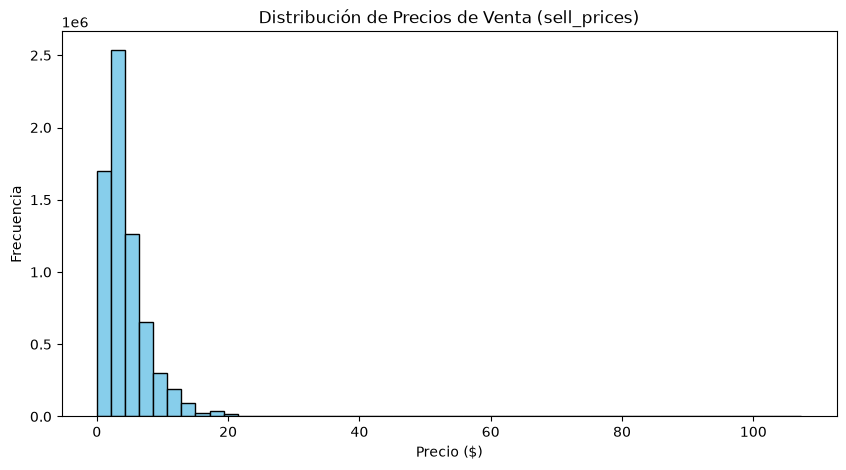

In [39]:
# Visualización opcional de la distribución de precios
plt.figure(figsize=(10, 5))
plt.hist(df_prices['sell_price'], bins=50, color='skyblue', edgecolor='black')
plt.title('Distribución de Precios de Venta (sell_prices)')
plt.xlabel('Precio ($)')
plt.ylabel('Frecuencia')
plt.show()

#### 7. Sales Train Evaluation/Validation

##### Diccionario de Datos: `sales_train_evaluation.csv` (y `validation`)

Esta tabla contiene la serie temporal histórica de ventas unitarias diarias en formato ancho (*wide format*). Cada fila representa una serie temporal única (combinación de producto y tienda) a lo largo de 1.941 días históricos.

Columnas de Jerarquía y Metadatos:
* **`id`** (`str`): Identificador único de la serie temporal, estructurado como `[item_id]_[store_id]_[evaluation|validation]`.
* **`item_id`** (`str`): Identificador del producto / SKU (3.049 productos únicos).
* **`dept_id`** (`str`): Identificador del departamento (7 departamentos: *FOODS_1*, *FOODS_2*, *FOODS_3*, *HOBBIES_1*, *HOBBIES_2*, *HOUSEHOLD_1*, *HOUSEHOLD_2*).
* **`cat_id`** (`str`): Categoría del producto (3 categorías: *FOODS*, *HOBBIES*, *HOUSEHOLD*).
* **`store_id`** (`str`): Identificador de la tienda física (10 tiendas: *CA_1*, *CA_2*, *CA_3*, *CA_4*, *TX_1*, *TX_2*, *TX_3*, *WI_1*, *WI_2*, *WI_3*).
* **`state_id`** (`str`): Estado donde se ubica la tienda (3 estados: *CA*, *TX*, *WI*).

Columnas de Ventas Diarias:
* **`d_1` a `d_1941`** (`int64`): Cantidad entera de unidades vendidas de ese producto en esa tienda durante cada día.
  * En `sales_train_validation.csv` la serie termina en `d_1913`.
  * En `sales_train_evaluation.csv` la serie incluye 28 días adicionales, finalizando en `d_1941`.
  * **Intermitencia:** La gran mayoría de valores en estas columnas son ceros, reflejando patrones de demanda esporádica habituales en retail.

In [40]:
df_eval = dfs_m5['sales_train_evaluation']
df_val = dfs_m5['sales_train_validation']

# 1. Comparativa de dimensiones y días extra
print("=== COMPARATIVA DE DIMENSIONES ===")
print(f"sales_train_validation : {df_val.shape[0]:,} filas x {df_val.shape[1]} columnas")
print(f"sales_train_evaluation : {df_eval.shape[0]:,} filas x {df_eval.shape[1]} columnas")

dias_extra = [c for c in df_eval.columns if c not in df_val.columns]
print(f"Días adicionales en evaluation ({len(dias_extra)} días): del {dias_extra[0]} al {dias_extra[-1]}")

# 2. Jerarquía categórica (columnas ID)
id_cols = ['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id']
day_cols = [c for c in df_eval.columns if c.startswith('d_')]

print("\n=== JERARQUÍA Y VALORES NULOS ===")
display(pd.DataFrame({
    'Columna': id_cols,
    'Dtype': [str(df_eval[c].dtype) for c in id_cols],
    'Nulos': [df_eval[c].isnull().sum() for c in id_cols],
    'Valores_Únicos': [df_eval[c].nunique() for c in id_cols]
}))

# 3. Nivel de intermitencia (porcentaje de ceros en la matriz de ventas)
ventas_matriz = df_eval[day_cols].values
total_observaciones = ventas_matriz.size
total_ceros = np.count_nonzero(ventas_matriz == 0)
pct_ceros = (total_ceros / total_observaciones) * 100

print("\n=== INTERMITENCIA DE LA DEMANDA ===")
print(f"Total de registros unitarios (series x días): {total_observaciones:,}")
print(f"Total registros con 0 unidades vendidas: {total_ceros:,} ({pct_ceros:.2f}%)")

# 4. Distribución de ventas totales diarias agregadas
print("\n=== RESUMEN DE VENTAS TOTALES DIARIAS DE LA CADENA ===")
ventas_diarias = df_eval[day_cols].sum(axis=0)
display(ventas_diarias.describe().round(2).to_frame(name="Ventas_Cadena_Día").T)

=== COMPARATIVA DE DIMENSIONES ===
sales_train_validation : 30,490 filas x 1919 columnas
sales_train_evaluation : 30,490 filas x 1947 columnas
Días adicionales en evaluation (28 días): del d_1914 al d_1941

=== JERARQUÍA Y VALORES NULOS ===


,Columna,Dtype,Nulos,Valores_Únicos
0,id,str,0,30490
1,item_id,str,0,3049
2,dept_id,str,0,7
3,cat_id,str,0,3
4,store_id,str,0,10
5,state_id,str,0,3



=== INTERMITENCIA DE LA DEMANDA ===
Total de registros unitarios (series x días): 59,181,090
Total registros con 0 unidades vendidas: 40,241,819 (68.00%)

=== RESUMEN DE VENTAS TOTALES DIARIAS DE LA CADENA ===


,count,mean,std,min,25%,50%,75%,max
Ventas_Cadena_Día,1941.0,34480.77,7425.91,11.0,29713.0,33830.0,39008.0,59921.0


In [41]:
# Both tables contain the same data, but evaluation contains 28 more days of data
(df_eval.iloc[:, :-28].iloc[:, 1:]!=df_val.iloc[:, 1:]).sum().sum()

np.int64(0)

#### 8. Sample Submission

In [42]:
df_sub = dfs_m5['sample_submission']

print("=== INFORMACIÓN GENERAL Y DIMENSIONES ===")
print(f"Dimensiones: {df_sub.shape[0]:,} filas x {df_sub.shape[1]} columnas")
print(f"Total de valores nulos: {df_sub.isnull().sum().sum()}")

print("\n=== TIPOS DE DATOS DE LAS COLUMNAS ===")
print(df_sub.dtypes.value_counts())

print("\n=== DISTRIBUCIÓN DE SUFIJOS EN 'id' ===")
# Extraer si el registro pertenece a 'validation' o 'evaluation'
print(df_sub['id'].apply(lambda x: x.split('_')[-1]).value_counts())

print("\n=== PRIMERAS FILAS ===")
display(df_sub.head())

print("\n=== ÚLTIMAS FILAS ===")
display(df_sub.tail())

=== INFORMACIÓN GENERAL Y DIMENSIONES ===
Dimensiones: 60,980 filas x 29 columnas
Total de valores nulos: 0

=== TIPOS DE DATOS DE LAS COLUMNAS ===
int64    28
str       1
Name: count, dtype: int64

=== DISTRIBUCIÓN DE SUFIJOS EN 'id' ===
id
validation    30490
evaluation    30490
Name: count, dtype: int64

=== PRIMERAS FILAS ===


,id,F1,F2,F3,F4,F5,F6,F7,F8,F9,...,F19,F20,F21,F22,F23,F24,F25,F26,F27,F28
0,HOBBIES_1_001_CA_1_validation,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,HOBBIES_1_002_CA_1_validation,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,HOBBIES_1_003_CA_1_validation,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,HOBBIES_1_004_CA_1_validation,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,HOBBIES_1_005_CA_1_validation,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0



=== ÚLTIMAS FILAS ===


,id,F1,F2,F3,F4,F5,F6,F7,F8,F9,...,F19,F20,F21,F22,F23,F24,F25,F26,F27,F28
60975,FOODS_3_823_WI_3_evaluation,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
60976,FOODS_3_824_WI_3_evaluation,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
60977,FOODS_3_825_WI_3_evaluation,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
60978,FOODS_3_826_WI_3_evaluation,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
60979,FOODS_3_827_WI_3_evaluation,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


#### 9. Working Data

In [43]:
df_cal[df_cal.year == 2012]

,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
337,2012-01-01,11149,Sunday,2,1,2012,d_338,NewYear,National,NaN,NaN,1,1,0
338,2012-01-02,11149,Monday,3,1,2012,d_339,NaN,NaN,NaN,NaN,1,0,1
339,2012-01-03,11149,Tuesday,4,1,2012,d_340,NaN,NaN,NaN,NaN,1,1,1
340,2012-01-04,11149,Wednesday,5,1,2012,d_341,NaN,NaN,NaN,NaN,1,0,0
341,2012-01-05,11149,Thursday,6,1,2012,d_342,NaN,NaN,NaN,NaN,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
698,2012-12-27,11248,Thursday,6,12,2012,d_699,NaN,NaN,NaN,NaN,0,0,0
699,2012-12-28,11248,Friday,7,12,2012,d_700,NaN,NaN,NaN,NaN,0,0,0
700,2012-12-29,11249,Saturday,1,12,2012,d_701,NaN,NaN,NaN,NaN,0,0,0
701,2012-12-30,11249,Sunday,2,12,2012,d_702,NaN,NaN,NaN,NaN,0,0,0
